**Image Data Exploration and OCR**

This project aims to classify images as Alcohol or Non-Alcohol based on their text content.

The pipeline combines OCR for text extraction and NLP for classification. The notebook covers data exploration, preprocessing, model development, and performance evaluation.

Run from the repository root using the environment described in `README.md`.

In [64]:
test_mode = False # Set to True to run on a small test dataset, False to run on the full dataset

# Imports

In [65]:
from pathlib import Path

import easyocr
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
from PIL import Image, ImageOps
from scipy import sparse
from sentence_transformers import SentenceTransformer
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    auc,
    classification_report,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
from xgboost import XGBClassifier


if test_mode:
    DATA_DIR = Path("images_test")
    RESULTS_DIR = Path("results_test")
else:
    DATA_DIR = Path("images")
    RESULTS_DIR = Path("results")

RESULTS_DIR.mkdir(exist_ok=True)
DATA_RESULTS_DIR = RESULTS_DIR / "data"
OCR_RESULTS_DIR = RESULTS_DIR / "ocr"
DATA_RESULTS_DIR.mkdir(exist_ok=True)
OCR_RESULTS_DIR.mkdir(exist_ok=True)

pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update(
    {"font.size": 16, "axes.titlesize": 20, "axes.labelsize": 18}
)

# Limit CPU threads to avoid excessive overhead on these small images.
torch.set_num_threads(4)

# Data

Use the parent folder as the label: `alcohol` or `non_alcohol`. Load each image to check it is readable and collect its dimensions, format, and file size. Keep file paths rather than all image pixels in memory.

Save dataset metadata, statistics, and sample figures in the `data/` subfolder of the selected results folder.

## Load Dataset

In [66]:
def load_image_dataset(data_dir):
    """Load image paths, folder labels, and basic image metadata.

    Args:
        data_dir (Path): Directory containing alcohol and non_alcohol folders.

    Returns:
        pd.DataFrame: One row per image with its path, label, and metadata.
    """
    records = []
    image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

    for label in ("alcohol", "non_alcohol"):
        for image_path in sorted((data_dir / label).iterdir()):
            if image_path.suffix.lower() not in image_extensions:
                continue
            with Image.open(image_path) as image:
                image.load()
                width, height = ImageOps.exif_transpose(image).size
                records.append(
                    {
                        "file_name": image_path.name,
                        "image_path": str(image_path),
                        "label": label,
                        "width": width,
                        "height": height,
                        "format": image.format,
                        "mode": image.mode,
                        "file_size_kb": image_path.stat().st_size / 1024,
                    }
                )

    return pd.DataFrame(records)

In [67]:
dataset = load_image_dataset(DATA_DIR)
display(dataset.sample(10))

,file_name,image_path,label,width,height,format,mode,file_size_kb
520,3066a.jpg,images/alcohol/3066a.jpg,alcohol,500,325,JPEG,RGB,90.20
1099,3100na.jpg,images/non_alcohol/3100na.jpg,non_alcohol,640,426,JPEG,RGB,174.58
882,0357na.jpg,images/non_alcohol/0357na.jpg,non_alcohol,426,640,JPEG,RGB,130.15
731,0195na.jpg,images/non_alcohol/0195na.jpg,non_alcohol,640,427,JPEG,RGB,141.62
711,0174na.jpg,images/non_alcohol/0174na.jpg,non_alcohol,640,426,JPEG,RGB,137.39
135,0147a.jpg,images/alcohol/0147a.jpg,alcohol,640,480,JPEG,RGB,153.42
442,0482a.jpg,images/alcohol/0482a.jpg,alcohol,640,480,JPEG,RGB,161.19
807,0276na.jpg,images/non_alcohol/0276na.jpg,non_alcohol,640,427,JPEG,RGB,120.59
875,0349na.jpg,images/non_alcohol/0349na.jpg,non_alcohol,640,632,JPEG,RGB,268.48
743,0208na.jpg,images/non_alcohol/0208na.jpg,non_alcohol,612,612,JPEG,RGB,105.33


## Datasets Statistics

Total images: 1,100
Total file size: 138.54 MB


,file_name,image_path,label,width,height,format,mode,file_size_kb
0,0000a.jpg,images/alcohol/0000a.jpg,alcohol,640,427,JPEG,RGB,149.35
1,0001a.jpg,images/alcohol/0001a.jpg,alcohol,314,500,JPEG,RGB,89.23
2,0003a.jpg,images/alcohol/0003a.jpg,alcohol,640,427,JPEG,RGB,201.13
3,0004a.jpg,images/alcohol/0004a.jpg,alcohol,500,438,JPEG,RGB,95.90
4,0005a.jpg,images/alcohol/0005a.jpg,alcohol,640,480,JPEG,RGB,142.84


,image_count,percentage
label,,
alcohol,550,50.00
non_alcohol,550,50.00


,count,mean,std,min,25%,50%,75%,max
width,"1,100.00",573.98,94.99,238.00,500.00,640.00,640.00,640.00
height,"1,100.00",482.82,100.07,180.00,426.00,480.00,512.25,640.00
file_size_kb,"1,100.00",128.97,44.39,14.46,96.80,126.24,154.37,355.79


,,image_count
format,mode,
JPEG,RGB,1100


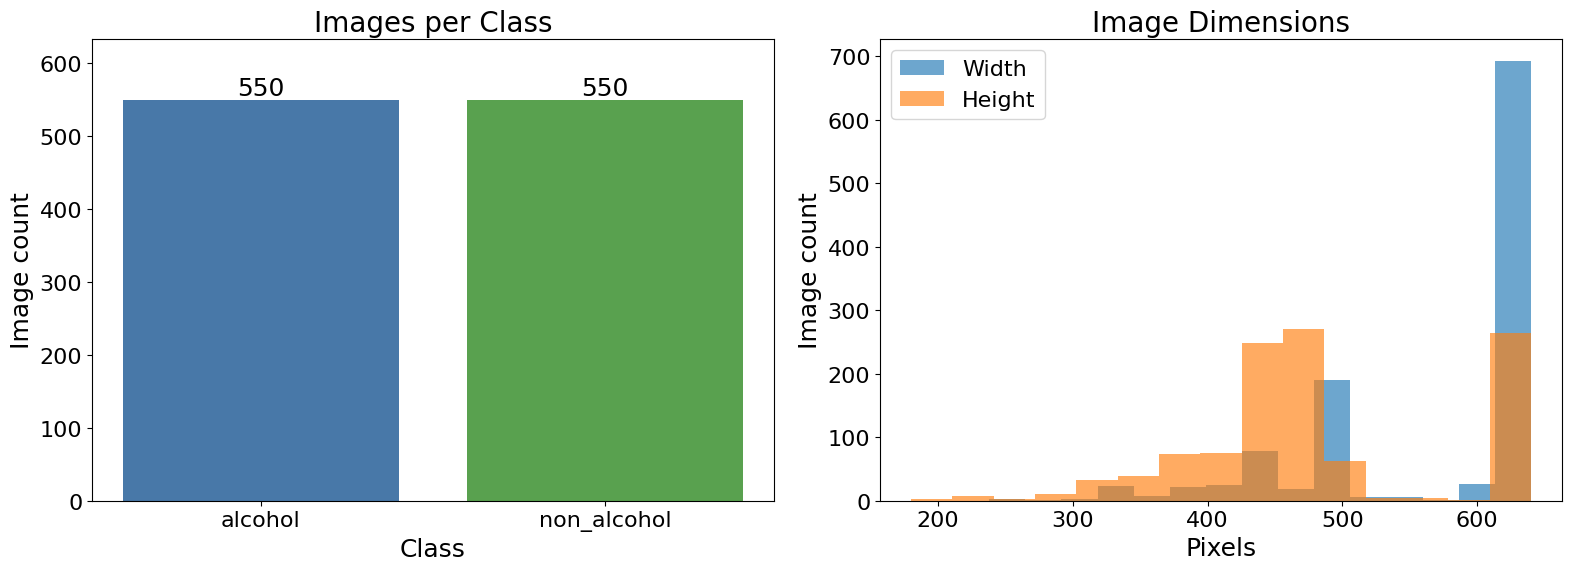

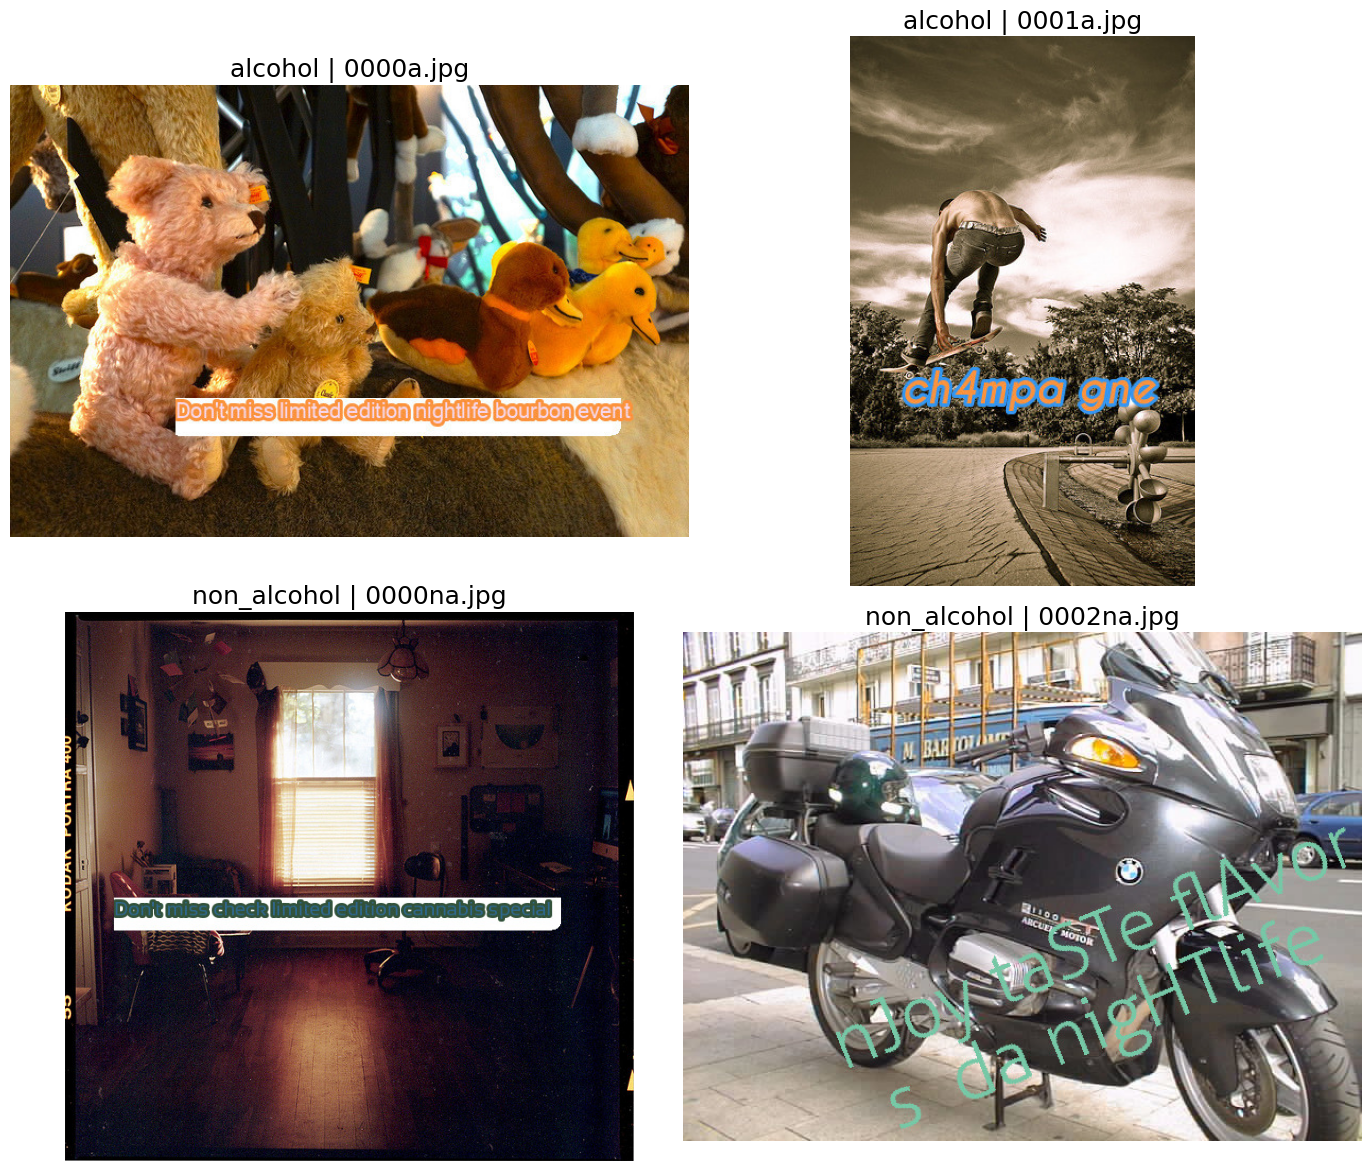

In [68]:
class_summary = dataset.groupby("label").size().rename("image_count").to_frame()
class_summary["percentage"] = class_summary["image_count"] / len(dataset) * 100
image_statistics = dataset[["width", "height", "file_size_kb"]].describe().T

print(f"Total images: {len(dataset):,}")
print(f"Total file size: {dataset['file_size_kb'].sum() / 1024:,.2f} MB")
display(dataset.head())
display(
    class_summary.style.format(
        {"image_count": "{:,.0f}", "percentage": "{:,.2f}"}
    )
)
display(image_statistics)
display(
    dataset.groupby(["format", "mode"]).size().rename("image_count").to_frame()
)

dataset.to_csv(DATA_RESULTS_DIR / "image_metadata.csv", index=False)
class_summary.to_csv(DATA_RESULTS_DIR / "class_summary.csv")
image_statistics.to_csv(DATA_RESULTS_DIR / "image_statistics.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].bar(
    class_summary.index,
    class_summary["image_count"],
    color=["#4878A8", "#59A14F"],
)
axes[0].set(title="Images per Class", xlabel="Class", ylabel="Image count")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
for position, count in enumerate(class_summary["image_count"]):
    axes[0].text(
        position, count, f"{count:,}", ha="center", va="bottom", fontsize=18
    )
axes[0].set_ylim(0, class_summary["image_count"].max() * 1.15)

axes[1].hist(dataset["width"], bins=15, alpha=0.65, label="Width")
axes[1].hist(dataset["height"], bins=15, alpha=0.65, label="Height")
axes[1].set(title="Image Dimensions", xlabel="Pixels", ylabel="Image count")
axes[1].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].legend()
fig.tight_layout()
fig.savefig(
    DATA_RESULTS_DIR / "dataset_statistics.png", dpi=150, bbox_inches="tight"
)
plt.show()

# Show the first two images in each class for a reproducible visual check.
examples = dataset.groupby("label", sort=True).head(2)
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for axis, row in zip(axes.flat, examples.itertuples(index=False)):
    with Image.open(row.image_path) as image:
        axis.imshow(ImageOps.exif_transpose(image).convert("RGB"))
    axis.set_title(f"{row.label} | {row.file_name}", fontsize=18)
    axis.axis("off")
fig.tight_layout()
fig.savefig(DATA_RESULTS_DIR / "sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

# Extract Text

Use [EasyOCR](https://www.jaided.ai/easyocr/documentation/), one of the libraries suggested in the assignment, with English recognition and `gpu=False`. Initialize the reader once and use its default detection and recognition settings for this first pass. On first use, EasyOCR downloads its pretrained models into `.cache/easyocr/`; later runs reuse them.

Keep recognized text without a confidence cutoff so uncertain words remain available for inspection. Store mean confidence per image on EasyOCR's 0–1 scale; an image without detected text has an empty string and missing confidence. Joining detected text boxes with spaces provides a simple text column, without assuming a reliable reading order.

OCR coverage and confidence describe extraction behavior. They do not measure transcription accuracy because the dataset does not provide reference transcriptions.

Reuse `OCR_RESULTS_DIR / "ocr_text.csv"` when it exists, skipping both model initialization and text extraction. Otherwise, run OCR and save the results for later runs. The selected test/full mode uses its own results folder. To rerun OCR after changing the images or OCR settings, remove the saved CSV first.

Save extracted text, OCR summaries, and OCR figures in the `ocr/` subfolder of the selected results folder.

## OCR

In [69]:
def create_ocr_reader(model_dir):
    """Initialize an English EasyOCR reader for CPU-only execution.

    Args:
        model_dir (Path): Local directory for downloaded OCR model weights.

    Returns:
        easyocr.Reader: Reader shared across all images.
    """
    return easyocr.Reader(
        ["en"],
        # gpu=False,
        model_storage_directory=str(model_dir),
        user_network_directory=str(model_dir / "user_network"),
        verbose=True,
    )


def extract_image_text(dataset, reader):
    """Extract text and confidence information from every dataset image.

    Args:
        dataset (pd.DataFrame): Image metadata including image_path.
        reader (easyocr.Reader): Initialized OCR reader.

    Returns:
        pd.DataFrame: Metadata with extracted text, word counts, detected
            text-box counts, and mean recognition confidence per image.
    """
    records = []
    for row in tqdm(
        dataset.itertuples(index=False), total=len(dataset), desc="OCR"
    ):
        with Image.open(row.image_path) as image:
            image_array = np.array(
                ImageOps.exif_transpose(image).convert("RGB")
            )
        detections = reader.readtext(image_array, detail=1, paragraph=False)
        text_parts = [text for _, text, _ in detections if text.strip()]
        confidences = [
            float(confidence)
            for _, text, confidence in detections
            if text.strip()
        ]
        extracted_text = " ".join(text_parts)
        records.append(
            {
                "extracted_text": extracted_text,
                "word_count": len(extracted_text.split()),
                "text_box_count": len(text_parts),
                "mean_confidence": (
                    np.mean(confidences) if confidences else np.nan
                ),
            }
        )

    return pd.concat(
        [dataset.reset_index(drop=True), pd.DataFrame(records)], axis=1
    )

In [ ]:
ocr_results_path = OCR_RESULTS_DIR / "ocr_text.csv"
if ocr_results_path.is_file():
    ocr_results = pd.read_csv(
        ocr_results_path,
        dtype={"extracted_text": str},
        keep_default_na=False,
        na_values={"mean_confidence": [""]},
    )
    print(
        f"Loaded OCR results for {len(ocr_results):,} images from {ocr_results_path}"
    )
else:
    ocr_reader = create_ocr_reader(Path(".cache") / "easyocr")
    ocr_results = extract_image_text(dataset, ocr_reader)
    ocr_results.to_csv(ocr_results_path, index=False)
    print(f"Saved OCR results to {ocr_results_path}")

display(ocr_results.sample(10))

Images with extracted text: 1,075 / 1,100


,image_count,images_with_text,mean_word_count,mean_confidence,images_without_text,text_coverage_percent
label,,,,,,
alcohol,550,535,4.42,0.52,15,97.27
non_alcohol,550,540,4.60,0.51,10,98.18


,file_name,label,extracted_text,word_count,mean_confidence
0,0000a.jpg,alcohol,Donlmisslimitededitionnighilifebourbonevent,1,0.49
1,0001a.jpg,alcohol,chAnpa 013,2,0.31
2,0003a.jpg,alcohol,Dont Ims9 0ob now Te3TEJEE3Z7E pemim,6,0.35
550,0000na.jpg,non_alcohol,) { 3 Dontmiescheclumiededitoncannab 3cpeca],5,0.54
551,0002na.jpg,non_alcohol,5 Y flAvor/ LaSTe nighTlite nsey,6,0.38
552,0005na.jpg,non_alcohol,benoqal 99ii05,2,0.20


Images without detected text (up to five examples):


,file_name,label
24,0026a.jpg,alcohol
30,0032a.jpg,alcohol
52,0057a.jpg,alcohol
77,0085a.jpg,alcohol
101,0110a.jpg,alcohol


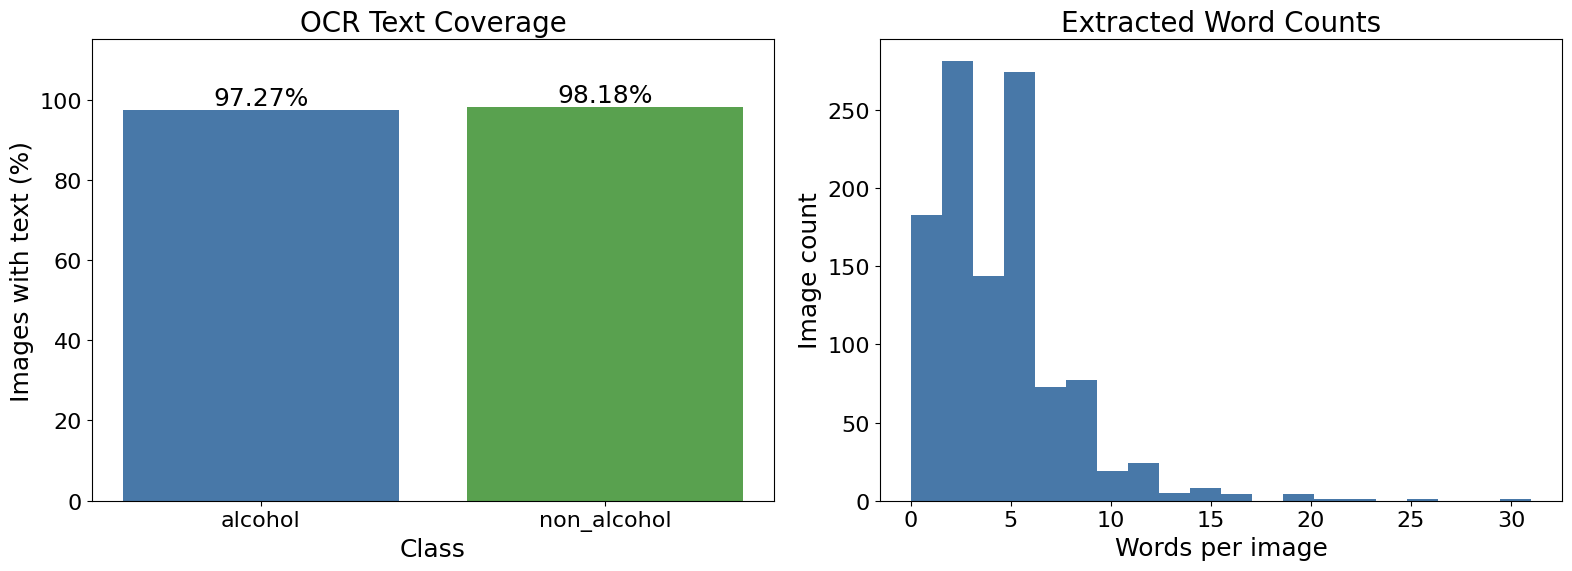

In [71]:
ocr_summary = (
    ocr_results.assign(has_text=ocr_results["word_count"].gt(0))
    .groupby("label")
    .agg(
        image_count=("file_name", "size"),
        images_with_text=("has_text", "sum"),
        mean_word_count=("word_count", "mean"),
        mean_confidence=("mean_confidence", "mean"),
    )
)
ocr_summary["images_without_text"] = (
    ocr_summary["image_count"] - ocr_summary["images_with_text"]
)
ocr_summary["text_coverage_percent"] = (
    ocr_summary["images_with_text"] / ocr_summary["image_count"] * 100
)
ocr_summary.to_csv(OCR_RESULTS_DIR / "ocr_summary.csv")

print(
    f"Images with extracted text: {ocr_results['word_count'].gt(0).sum():,} / {len(ocr_results):,}"
)
display(ocr_summary)
display(
    ocr_results.groupby("label", sort=True)
    .head(3)[
        [
            "file_name",
            "label",
            "extracted_text",
            "word_count",
            "mean_confidence",
        ]
    ]
    .style.format(
        {"word_count": "{:,.0f}", "mean_confidence": "{:,.2f}"}, na_rep="N/A"
    )
)
print("Images without detected text (up to five examples):")
display(
    ocr_results.loc[
        ocr_results["word_count"].eq(0), ["file_name", "label"]
    ].head()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].bar(
    ocr_summary.index,
    ocr_summary["text_coverage_percent"],
    color=["#4878A8", "#59A14F"],
)
axes[0].set(
    title="OCR Text Coverage",
    xlabel="Class",
    ylabel="Images with text (%)",
    ylim=(0, 115),
)
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
for position, coverage in enumerate(ocr_summary["text_coverage_percent"]):
    axes[0].text(
        position,
        coverage,
        f"{coverage:,.2f}%",
        ha="center",
        va="bottom",
        fontsize=18,
    )

axes[1].hist(ocr_results["word_count"], bins=20, color="#4878A8")
axes[1].set(
    title="Extracted Word Counts",
    xlabel="Words per image",
    ylabel="Image count",
)
axes[1].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
fig.tight_layout()
fig.savefig(OCR_RESULTS_DIR / "ocr_statistics.png", dpi=150, bbox_inches="tight")
plt.show()

# Text Embedding

Convert text into one feature vector per image using two representations.

In [72]:
EMBEDDING_RESULTS_DIR = RESULTS_DIR / "embeddings"
TFIDF_RESULTS_DIR = EMBEDDING_RESULTS_DIR / "tfidf"
BERT_RESULTS_DIR = EMBEDDING_RESULTS_DIR / "bert"
TFIDF_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
BERT_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [73]:
embedding_texts = (
    ocr_results["extracted_text"]
    .fillna("")
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .reset_index(drop=True)
)
embedding_metadata = ocr_results[
    ["file_name", "image_path", "label"]
].reset_index(drop=True)
embedding_metadata.insert(0, "embedding_row", np.arange(len(embedding_texts)))
embedding_metadata["extracted_text"] = embedding_texts
embedding_metadata["has_text"] = embedding_texts.ne("")

embedding_metadata.to_csv(
    EMBEDDING_RESULTS_DIR / "embedding_metadata.csv", index=False
)

## TF-IDF

Use [character TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) with 3–5-character fragments within word boundaries.  
This keeps fragments inside OCR words that lost their spaces and provides a simple representation of partially recognized terms.  
Empty text produces a zero vector.

In [74]:
def create_tfidf_embeddings(texts, max_features=5000):
    """Fit character TF-IDF features to the supplied OCR text.

    Args:
        texts (pd.Series): OCR text with missing values replaced by strings.
        max_features (int): Maximum number of character features to keep.

    Returns:
        tuple: Sparse TF-IDF matrix and its fitted TfidfVectorizer. Matrix
            rows follow the input text order.

    Raises:
        ValueError: If no nonempty OCR text is available to fit a vocabulary.
    """
    if not texts.str.strip().ne("").any():
        raise ValueError("TF-IDF needs at least one nonempty OCR result.")

    vectorizer = TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 5),
        max_features=max_features,
        sublinear_tf=True,
        norm="l2",
        dtype=np.float32,
    )
    embeddings = vectorizer.fit_transform(texts.tolist())
    return embeddings, vectorizer

In [75]:
tfidf_embeddings, tfidf_vectorizer = create_tfidf_embeddings(embedding_texts)
sparse.save_npz(
    TFIDF_RESULTS_DIR / "tfidf_embeddings.npz", tfidf_embeddings
)
joblib.dump(tfidf_vectorizer, TFIDF_RESULTS_DIR / "tfidf_vectorizer.joblib")

['results/embeddings/tfidf/tfidf_vectorizer.joblib']

,images,features,nonzero_values,sparsity_percent,zero_vectors
TF-IDF,1100,5000,41056,99.25,26


,feature_index,character_fragment,idf,mean_tfidf
2316,2316,er,3.04,0.01
284,284,ch,2.97,0.01
2097,2097,ed,3.08,0.01
2083,2083,eck,3.12,0.01
1782,1782,ck,3.15,0.01
1754,1754,che,3.12,0.01
2601,2601,hec,3.15,0.01
1755,1755,chec,3.20,0.01
2605,2605,heck,3.20,0.01
291,291,che,3.22,0.01


,embedding_row,file_name,image_path,label,extracted_text,has_text
0,0,0000a.jpg,images/alcohol/0000a.jpg,alcohol,Donlmisslimitededitionnighilifebourbonevent,True
1,1,0001a.jpg,images/alcohol/0001a.jpg,alcohol,chAnpa 013,True
2,2,0003a.jpg,images/alcohol/0003a.jpg,alcohol,Dont Ims9 0ob now Te3TEJEE3Z7E pemim,True
3,3,0004a.jpg,images/alcohol/0004a.jpg,alcohol,QHAMAVAWAX 'DMAV aed,True
4,4,0005a.jpg,images/alcohol/0005a.jpg,alcohol,Douftmisslimited editionlited editiom port imp...,True


,er,ch,ed,eck,ck,che,hec,chec
file_name,,,,,,,,
0000a.jpg,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
0001a.jpg,0.00,0.14,0.00,0.00,0.00,0.00,0.00,0.00
0003a.jpg,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
0004a.jpg,0.00,0.00,0.13,0.00,0.00,0.00,0.00,0.00
0005a.jpg,0.00,0.00,0.12,0.00,0.00,0.00,0.00,0.00


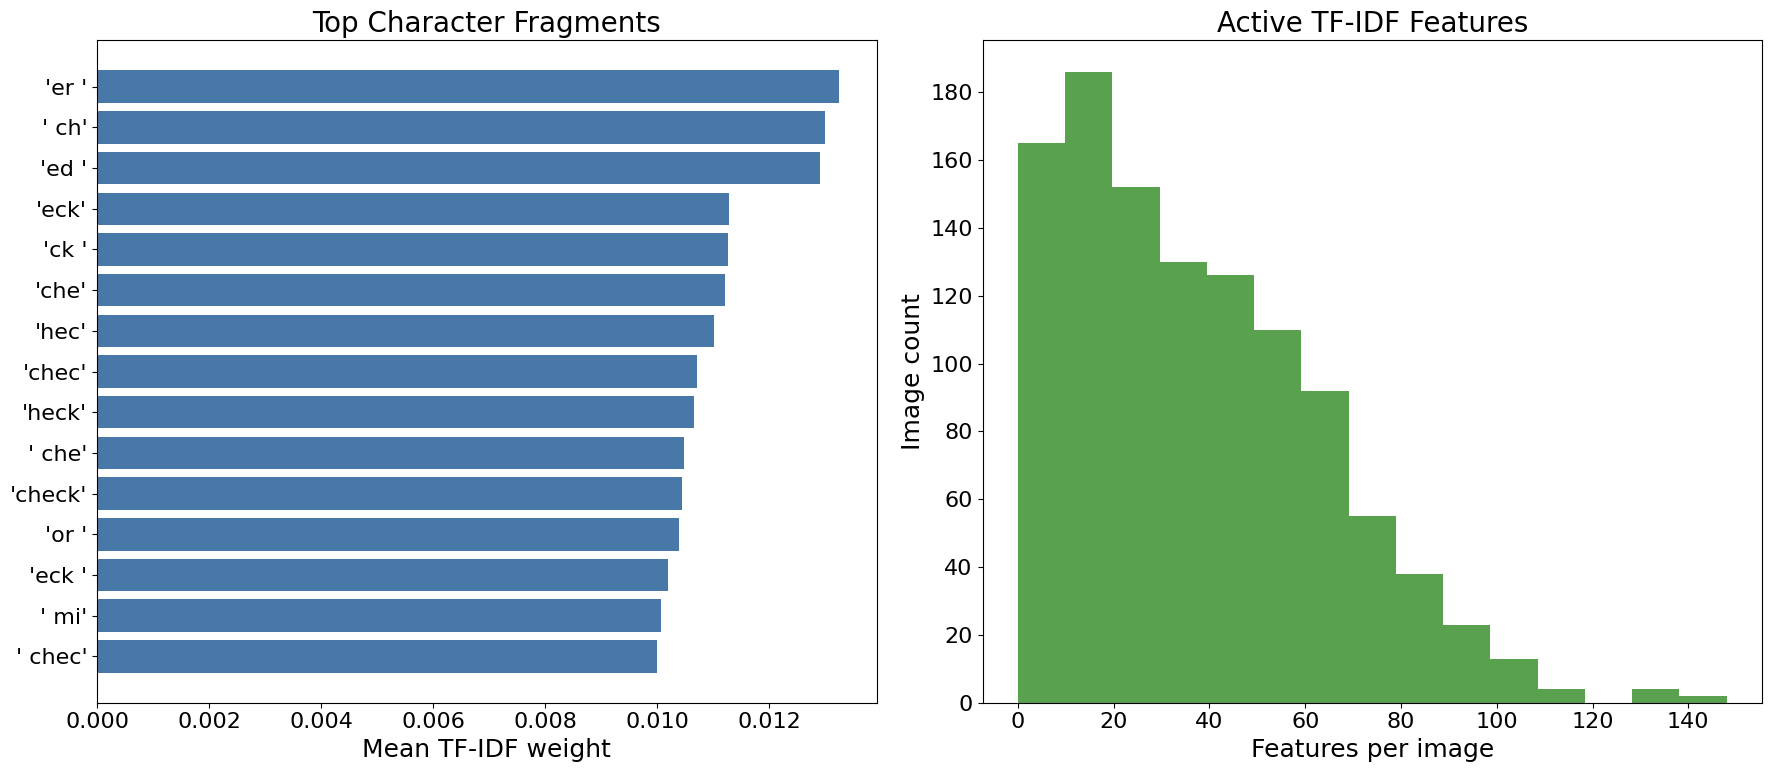

In [76]:
tfidf_summary = pd.DataFrame(
    {
        "images": [tfidf_embeddings.shape[0]],
        "features": [tfidf_embeddings.shape[1]],
        "nonzero_values": [tfidf_embeddings.nnz],
        "sparsity_percent": [
            (1 - tfidf_embeddings.nnz / np.prod(tfidf_embeddings.shape)) * 100
        ],
        "zero_vectors": [
            np.count_nonzero(tfidf_embeddings.getnnz(axis=1) == 0)
        ],
    },
    index=["TF-IDF"],
)
tfidf_features = pd.DataFrame(
    {
        "feature_index": np.arange(tfidf_embeddings.shape[1]),
        "character_fragment": tfidf_vectorizer.get_feature_names_out(),
        "idf": tfidf_vectorizer.idf_,
        "mean_tfidf": np.asarray(tfidf_embeddings.mean(axis=0)).ravel(),
    }
)
top_features = tfidf_features.nlargest(15, "mean_tfidf")
preview_features = top_features["feature_index"].head(8).to_numpy()

display(tfidf_summary)
display(top_features)
display(embedding_metadata.head())
display(
    pd.DataFrame(
        tfidf_embeddings[:5, preview_features].toarray(),
        index=embedding_metadata["file_name"].head(5),
        columns=tfidf_vectorizer.get_feature_names_out()[preview_features],
    )
)
tfidf_summary.to_csv(TFIDF_RESULTS_DIR / "tfidf_summary.csv", index=False)
tfidf_features.to_csv(TFIDF_RESULTS_DIR / "tfidf_features.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
axes[0].barh(
    [repr(fragment) for fragment in top_features["character_fragment"]],
    top_features["mean_tfidf"],
    color="#4878A8",
)
axes[0].invert_yaxis()
axes[0].set(title="Top Character Fragments", xlabel="Mean TF-IDF weight")
axes[0].xaxis.set_major_formatter(StrMethodFormatter("{x:,.3f}"))
axes[1].hist(tfidf_embeddings.getnnz(axis=1), bins=15, color="#59A14F")
axes[1].set(
    title="Active TF-IDF Features",
    xlabel="Features per image",
    ylabel="Image count",
)
axes[1].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
fig.tight_layout()
fig.savefig(
    TFIDF_RESULTS_DIR / "tfidf_statistics.png", dpi=150, bbox_inches="tight"
)
plt.show()

### PCA Visualization

Project TF-IDF embeddings onto two principal components and color the images by their folder labels. Use [PCA with the ARPACK solver](https://scikit-learn.org/1.6/modules/generated/sklearn.decomposition.PCA.html), which centers the features while accepting the sparse TF-IDF matrix. Exclude zero vectors so missing text does not form an artificial cluster. Axis labels show the percentage of variance explained by each component.

#### Function Definition

In [ ]:
def create_tfidf_pca_projection(embeddings, metadata):
    """Project nonzero sparse TF-IDF vectors onto two principal components.

    Args:
        embeddings (scipy.sparse.csr_matrix): TF-IDF vectors in image row order.
        metadata (pd.DataFrame): Corresponding image metadata and labels.

    Returns:
        tuple: Image metadata with pc1 and pc2 coordinates, and the fitted PCA.

    Raises:
        ValueError: If fewer than three nonzero vectors or features are available.
    """
    has_features = embeddings.getnnz(axis=1) > 0
    nonzero_embeddings = embeddings[has_features]
    if min(nonzero_embeddings.shape) <= 2:
        raise ValueError(
            "ARPACK PCA needs at least three nonzero images and features."
        )

    pca = PCA(n_components=2, svd_solver="arpack", random_state=42)
    coordinates = pca.fit_transform(nonzero_embeddings)
    projection = metadata.loc[has_features].copy()
    projection[["pc1", "pc2"]] = coordinates
    return projection, pca

#### Function Call

In [ ]:
tfidf_projection, tfidf_pca = create_tfidf_pca_projection(
    tfidf_embeddings, embedding_metadata
)

#### Results and Visualization

In [ ]:
tfidf_pca_summary = pd.DataFrame(
    {
        "component": ["PC1", "PC2"],
        "explained_variance_percent": tfidf_pca.explained_variance_ratio_ * 100,
    }
)
print(f"Images in PCA projection: {len(tfidf_projection):,}")
display(tfidf_pca_summary)
display(tfidf_projection[["file_name", "label", "pc1", "pc2"]].head())
tfidf_projection.to_csv(TFIDF_RESULTS_DIR / "tfidf_pca.csv", index=False)
tfidf_pca_summary.to_csv(
    TFIDF_RESULTS_DIR / "tfidf_pca_summary.csv", index=False
)

fig, axis = plt.subplots(figsize=(12, 8))
for label, color in (("alcohol", "#4878A8"), ("non_alcohol", "#59A14F")):
    points = tfidf_projection.loc[tfidf_projection["label"].eq(label)]
    axis.scatter(
        points["pc1"],
        points["pc2"],
        label=label,
        color=color,
        s=60,
        alpha=0.65,
    )
axis.set(
    title="TF-IDF Embeddings: PCA Projection",
    xlabel=f"PC1 ({tfidf_pca.explained_variance_ratio_[0] * 100:,.2f}% variance)",
    ylabel=f"PC2 ({tfidf_pca.explained_variance_ratio_[1] * 100:,.2f}% variance)",
)
axis.xaxis.set_major_formatter(StrMethodFormatter("{x:,.2f}"))
axis.yaxis.set_major_formatter(StrMethodFormatter("{x:,.2f}"))
axis.legend()
fig.tight_layout()
fig.savefig(TFIDF_RESULTS_DIR / "tfidf_pca.png", dpi=150, bbox_inches="tight")
plt.show()

## Bert-Based

Use [all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), a pretrained sentence encoder that returns 384-dimensional vectors. Run on the CPU in batches and L2-normalize nonempty text embeddings. Set empty-text embeddings to zero so they indicate missing OCR evidence.

First run downloads model files into `.cache/sentence_transformers/`, later runs reuse them.
Inputs longer than the model's token limit are truncated, so report their count below.

In [77]:
def create_bert_embeddings(texts, model, batch_size=32):
    """Encode nonempty OCR text and preserve zero vectors for empty text.

    Args:
        texts (pd.Series): OCR text with missing values replaced by strings.
        model (SentenceTransformer): Initialized CPU sentence encoder.
        batch_size (int): Number of texts to encode in each batch.

    Returns:
        np.ndarray: Float32 feature matrix in input row order. Nonempty
            vectors have unit L2 norm; empty text has an all-zero vector.
    """
    embeddings = np.zeros(
        (len(texts), model.get_sentence_embedding_dimension()), dtype=np.float32
    )
    has_text = texts.str.strip().ne("").to_numpy()
    if has_text.any():
        embeddings[has_text] = model.encode(
            texts.loc[has_text].tolist(),
            batch_size=batch_size,
            show_progress_bar=True,
            convert_to_numpy=True,
            normalize_embeddings=True,
        )
    return embeddings

In [78]:
bert_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    revision="1110a243fdf4706b3f48f1d95db1a4f5529b4d41",
    device="cpu",
    cache_folder=str(Path(".cache") / "sentence_transformers"),
)
bert_embeddings = create_bert_embeddings(embedding_texts, bert_model)
np.save(BERT_RESULTS_DIR / "bert_embeddings.npy", bert_embeddings)

Batches:   0%|          | 0/34 [00:00<?, ?it/s]

,images,dimensions,zero_vectors,max_tokens,truncated_texts
MiniLM,1100,384,25,256,0


,image_count,images_with_text,mean_token_count,truncated_texts
label,,,,
alcohol,550,535,11.46,0
non_alcohol,550,540,11.86,0


,file_name,label,token_count,vector_norm
0,0000a.jpg,alcohol,15,1.00
1,0001a.jpg,alcohol,6,1.00
2,0003a.jpg,alcohol,21,1.00
3,0004a.jpg,alcohol,13,1.00
4,0005a.jpg,alcohol,15,1.00


,dimension_0,dimension_1,dimension_2,dimension_3,dimension_4,dimension_5,dimension_6,dimension_7
file_name,,,,,,,,
0000a.jpg,-0.00,-0.01,0.06,-0.06,-0.03,0.02,0.12,0.03
0001a.jpg,-0.04,-0.03,-0.07,0.01,-0.00,0.00,0.07,0.05
0003a.jpg,-0.08,0.05,0.03,-0.01,-0.00,-0.05,0.16,0.10
0004a.jpg,-0.12,0.09,0.01,-0.05,-0.06,0.00,0.06,0.04
0005a.jpg,-0.05,0.01,0.01,-0.04,-0.01,-0.03,-0.09,0.05


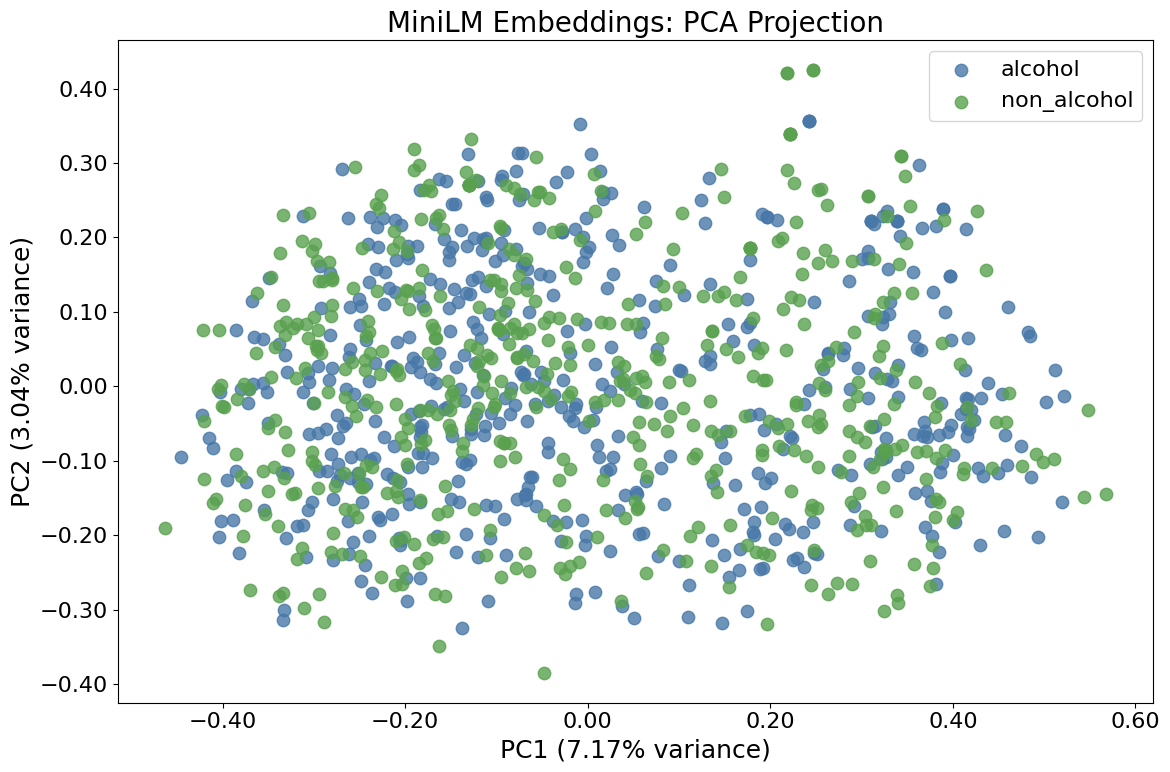

In [79]:
bert_metadata = embedding_metadata.copy()
bert_metadata["token_count"] = bert_model.tokenizer(
    embedding_texts.tolist(), truncation=False, return_length=True
)["length"]
bert_metadata["is_truncated"] = (
    bert_metadata["token_count"] > bert_model.max_seq_length
)
bert_metadata["vector_norm"] = np.linalg.norm(bert_embeddings, axis=1)
bert_summary = pd.DataFrame(
    {
        "images": [bert_embeddings.shape[0]],
        "dimensions": [bert_embeddings.shape[1]],
        "zero_vectors": [np.count_nonzero(bert_metadata["vector_norm"] == 0)],
        "max_tokens": [bert_model.max_seq_length],
        "truncated_texts": [bert_metadata["is_truncated"].sum()],
    },
    index=["MiniLM"],
)
bert_class_summary = bert_metadata.groupby("label").agg(
    image_count=("file_name", "size"),
    images_with_text=("has_text", "sum"),
    mean_token_count=("token_count", "mean"),
    truncated_texts=("is_truncated", "sum"),
)

display(bert_summary)
display(bert_class_summary)
display(
    bert_metadata[["file_name", "label", "token_count", "vector_norm"]].head()
)
display(
    pd.DataFrame(
        bert_embeddings[:5, :8],
        index=embedding_metadata["file_name"].head(5),
        columns=[f"dimension_{index}" for index in range(8)],
    )
)
bert_summary.to_csv(BERT_RESULTS_DIR / "bert_summary.csv", index=False)
bert_class_summary.to_csv(BERT_RESULTS_DIR / "bert_class_summary.csv")
bert_metadata.to_csv(BERT_RESULTS_DIR / "bert_metadata.csv", index=False)

# Exclude missing-text zero vectors from the semantic projection.
has_text = embedding_metadata["has_text"].to_numpy()
if has_text.sum() >= 2:
    pca = PCA(n_components=2, svd_solver="full")
    coordinates = pca.fit_transform(bert_embeddings[has_text])
    projection = embedding_metadata.loc[has_text].copy()
    projection[["pc1", "pc2"]] = coordinates
    projection.to_csv(BERT_RESULTS_DIR / "bert_pca.csv", index=False)

    fig, axis = plt.subplots(figsize=(12, 8))
    for label, color in (("alcohol", "#4878A8"), ("non_alcohol", "#59A14F")):
        points = projection.loc[projection["label"].eq(label)]
        axis.scatter(
            points["pc1"],
            points["pc2"],
            label=label,
            color=color,
            s=80,
            alpha=0.8,
        )
    axis.set(
        title="MiniLM Embeddings: PCA Projection",
        xlabel=f"PC1 ({pca.explained_variance_ratio_[0] * 100:,.2f}% variance)",
        ylabel=f"PC2 ({pca.explained_variance_ratio_[1] * 100:,.2f}% variance)",
    )
    axis.xaxis.set_major_formatter(StrMethodFormatter("{x:,.2f}"))
    axis.yaxis.set_major_formatter(StrMethodFormatter("{x:,.2f}"))
    axis.legend()
    fig.tight_layout()
    fig.savefig(
        BERT_RESULTS_DIR / "bert_pca.png", dpi=150, bbox_inches="tight"
    )
    plt.show()
else:
    print("PCA needs at least two images with extracted text.")

# Classification

Compare Logistic Regression, XGBoost, and Random Forest, each trained once with TF-IDF and once with MiniLM embeddings. All six runs use the same reproducible stratified split: 70% training and 30% held out. `alcohol` is the positive class (1); `non_alcohol` is class 0.

Refit TF-IDF on training text only and transform held-out text with that vectorizer. The earlier full-dataset TF-IDF matrix remains an exploration artifact. Reuse the pretrained BERT embeddings because their encoder was not fitted to this dataset; do not use the exploratory PCA coordinates for classification.

Report per-class precision, recall, F1, and support, plus accuracy, [ROC AUC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html), and [PR AUC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html). Both AUCs use alcohol probabilities, not predicted labels. PR AUC is the trapezoidal area under the precision–recall curve. Model settings and the 0.5 probability threshold are fixed before evaluation.

In test mode, the 20-image dataset provides only six held-out images. Those results verify the workflow; they are too small for reliable performance conclusions. The comparison does not tune models or select a final production model.

## Utils

In [80]:
def prepare_classification_data(
    texts,
    metadata,
    bert_embeddings,
    tfidf_vectorizer,
    test_size=0.3,
    random_state=42,
):
    """Create a shared held-out split and fit TF-IDF on training text only.

    Args:
        texts (pd.Series): Cleaned OCR text in embedding row order.
        metadata (pd.DataFrame): Image metadata including folder labels.
        bert_embeddings (np.ndarray): Pretrained sentence vectors in row order.
        tfidf_vectorizer (TfidfVectorizer): Template for TF-IDF settings.
        test_size (float): Fraction of images held out for evaluation.
        random_state (int): Seed for a reproducible stratified split.

    Returns:
        dict: Feature splits, training and test labels, test image metadata,
            complete split metadata, and the training-fitted vectorizer.
    """
    metadata = metadata.reset_index(drop=True)
    labels = metadata["label"].map({"non_alcohol": 0, "alcohol": 1}).to_numpy()
    train_indices, test_indices = train_test_split(
        np.arange(len(labels)),
        test_size=test_size,
        stratify=labels,
        random_state=random_state,
    )

    training_vectorizer = clone(tfidf_vectorizer)
    tfidf_train = training_vectorizer.fit_transform(texts.iloc[train_indices])
    tfidf_test = training_vectorizer.transform(texts.iloc[test_indices])
    split_metadata = metadata.copy()
    split_metadata["split"] = "train"
    split_metadata.loc[test_indices, "split"] = "test"

    return {
        "feature_splits": {
            "tfidf": (tfidf_train, tfidf_test),
            "bert": (
                bert_embeddings[train_indices],
                bert_embeddings[test_indices],
            ),
        },
        "y_train": labels[train_indices],
        "y_test": labels[test_indices],
        "test_metadata": metadata.iloc[test_indices].reset_index(drop=True),
        "split_metadata": split_metadata,
        "tfidf_vectorizer": training_vectorizer,
    }


def evaluate_embeddings(classifier, classification_data):
    """Fit separate classifier instances for TF-IDF and BERT and evaluate them.

    Args:
        classifier: Unfitted classifier supporting predict_proba.
        classification_data (dict): Features and labels from the shared split.

    Returns:
        dict: Per-embedding models, classification reports, metrics, held-out
            predictions, alcohol probabilities, and ROC and PR curve points.
    """
    results = {}
    y_train = classification_data["y_train"]
    y_test = classification_data["y_test"]
    for embedding_name, (x_train, x_test) in classification_data[
        "feature_splits"
    ].items():
        model = clone(classifier)
        model.fit(x_train, y_train)
        predictions = model.predict(x_test)
        positive_column = np.flatnonzero(model.classes_ == 1)[0]
        probabilities = model.predict_proba(x_test)[:, positive_column]
        report_values = classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["non_alcohol", "alcohol"],
            output_dict=True,
            zero_division=0,
        )
        accuracy = report_values.pop("accuracy")
        report = pd.DataFrame(report_values).T
        report.index.name = "class"
        fpr, tpr, _ = roc_curve(y_test, probabilities, pos_label=1)
        precision, recall, _ = precision_recall_curve(
            y_test, probabilities, pos_label=1
        )
        results[embedding_name] = {
            "model": model,
            "report": report,
            "metrics": {
                "train_images": len(y_train),
                "test_images": len(y_test),
                "accuracy": accuracy,
                "precision": report_values["alcohol"]["precision"],
                "recall": report_values["alcohol"]["recall"],
                "f1": report_values["alcohol"]["f1-score"],
                "macro_f1": report_values["macro avg"]["f1-score"],
                "roc_auc": roc_auc_score(y_test, probabilities),
                "pr_auc": auc(recall, precision),
            },
            "predictions": predictions,
            "probabilities": probabilities,
            "roc_curve": pd.DataFrame({"fpr": fpr, "tpr": tpr}),
            "pr_curve": pd.DataFrame(
                {"recall": recall, "precision": precision}
            ),
        }
    return results


def show_classifier_results(
    classifier_name, results, classification_data, output_dir
):
    """Display and save reports, predictions, models, and probability curves.

    Args:
        classifier_name (str): Name displayed in tables and plots.
        results (dict): Per-embedding output from evaluate_embeddings.
        classification_data (dict): Shared split with held-out image metadata.
        output_dir (Path): Classifier results directory.

    Returns:
        pd.DataFrame: Comparison metrics for the classifier's two embeddings.
    """
    summary_rows = []
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    for embedding_name, result in results.items():
        embedding_dir = output_dir / embedding_name
        embedding_dir.mkdir(parents=True, exist_ok=True)
        metrics = result["metrics"]
        summary_rows.append(
            {
                "classifier": classifier_name,
                "embedding": embedding_name,
                **metrics,
            }
        )
        print(f"{classifier_name} | {embedding_name.upper()}")
        display(
            result["report"].style.format(
                {
                    "precision": "{:,.3f}",
                    "recall": "{:,.3f}",
                    "f1-score": "{:,.3f}",
                    "support": "{:,.0f}",
                }
            )
        )
        print(
            f"ROC AUC: {metrics['roc_auc']:,.3f} | PR AUC: {metrics['pr_auc']:,.3f}"
        )
        result["report"].to_csv(embedding_dir / "classification_report.csv")
        pd.DataFrame([metrics]).to_csv(
            embedding_dir / "metrics.csv", index=False
        )
        result["roc_curve"].to_csv(embedding_dir / "roc_curve.csv", index=False)
        result["pr_curve"].to_csv(embedding_dir / "pr_curve.csv", index=False)
        joblib.dump(result["model"], embedding_dir / "classifier.joblib")

        predictions = classification_data["test_metadata"].copy()
        predictions["prediction"] = np.where(
            result["predictions"] == 1, "alcohol", "non_alcohol"
        )
        predictions["alcohol_probability"] = result["probabilities"]
        predictions["is_correct"] = predictions["prediction"].eq(
            predictions["label"]
        )
        predictions.to_csv(embedding_dir / "test_predictions.csv", index=False)

        roc_points = result["roc_curve"]
        pr_points = result["pr_curve"]
        axes[0].plot(
            roc_points["fpr"],
            roc_points["tpr"],
            linewidth=2.5,
            label=f"{embedding_name.upper()} (AUC={metrics['roc_auc']:,.3f})",
        )
        axes[1].plot(
            pr_points["recall"],
            pr_points["precision"],
            linewidth=2.5,
            label=f"{embedding_name.upper()} (AUC={metrics['pr_auc']:,.3f})",
        )

    axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Chance")
    prevalence = classification_data["y_test"].mean()
    axes[1].axhline(
        prevalence,
        linestyle="--",
        color="gray",
        label=f"Prevalence ({prevalence:,.2f})",
    )
    axes[0].set(
        title=f"{classifier_name}: ROC",
        xlabel="False positive rate",
        ylabel="True positive rate",
    )
    axes[1].set(
        title=f"{classifier_name}: Precision–Recall",
        xlabel="Recall",
        ylabel="Precision",
    )
    for axis in axes:
        axis.set(xlim=(0, 1), ylim=(0, 1.05))
        axis.xaxis.set_major_formatter(StrMethodFormatter("{x:,.2f}"))
        axis.yaxis.set_major_formatter(StrMethodFormatter("{x:,.2f}"))
        axis.legend(fontsize=13, loc="lower right")
    fig.tight_layout()
    fig.savefig(output_dir / "roc_pr_curves.png", dpi=150, bbox_inches="tight")
    plt.show()
    summary = pd.DataFrame(summary_rows)
    summary.to_csv(output_dir / "metrics_summary.csv", index=False)
    display(summary)
    return summary

## Preparations

In [81]:
CLASSIFICATION_RESULTS_DIR = RESULTS_DIR / "classification"
CLASSIFICATION_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
classification_data = prepare_classification_data(
    embedding_texts, embedding_metadata, bert_embeddings, tfidf_vectorizer
)
classification_data["split_metadata"].to_csv(
    CLASSIFICATION_RESULTS_DIR / "data_split.csv", index=False
)
joblib.dump(
    classification_data["tfidf_vectorizer"],
    CLASSIFICATION_RESULTS_DIR / "tfidf_training_vectorizer.joblib",
)

['results/classification/tfidf_training_vectorizer.joblib']

In [82]:
split_summary = (
    classification_data["split_metadata"]
    .groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
)
print(f"Training images: {len(classification_data['y_train']):,}")
print(f"Held-out images: {len(classification_data['y_test']):,}")
if test_mode:
    print("Test mode: these metrics are workflow checks on a small dataset.")
display(split_summary)
split_summary.to_csv(CLASSIFICATION_RESULTS_DIR / "split_summary.csv")

Training images: 770
Held-out images: 330


label,alcohol,non_alcohol
split,,
test,165,165
train,385,385


## Logistic Regression

A linear baseline for normalized sparse TF-IDF and dense MiniLM features. Use the same settings for both representations, with up to 1,000 iterations.

### Function Definition

In [83]:
def run_logistic_regression(classification_data):
    """Train and evaluate Logistic Regression once per embedding type.

    Args:
        classification_data (dict): Shared feature splits and labels.

    Returns:
        dict: TF-IDF and BERT evaluation results.
    """
    classifier = LogisticRegression(max_iter=1000, random_state=42)
    return evaluate_embeddings(classifier, classification_data)

In [84]:
logistic_results = run_logistic_regression(classification_data)

Logistic Regression | TFIDF


,precision,recall,f1-score,support
class,,,,
non_alcohol,0.830,0.861,0.845,165
alcohol,0.855,0.824,0.840,165
macro avg,0.843,0.842,0.842,330
weighted avg,0.843,0.842,0.842,330


ROC AUC: 0.948 | PR AUC: 0.952
Logistic Regression | BERT


,precision,recall,f1-score,support
class,,,,
non_alcohol,0.738,0.818,0.776,165
alcohol,0.796,0.709,0.750,165
macro avg,0.767,0.764,0.763,330
weighted avg,0.767,0.764,0.763,330


ROC AUC: 0.845 | PR AUC: 0.825


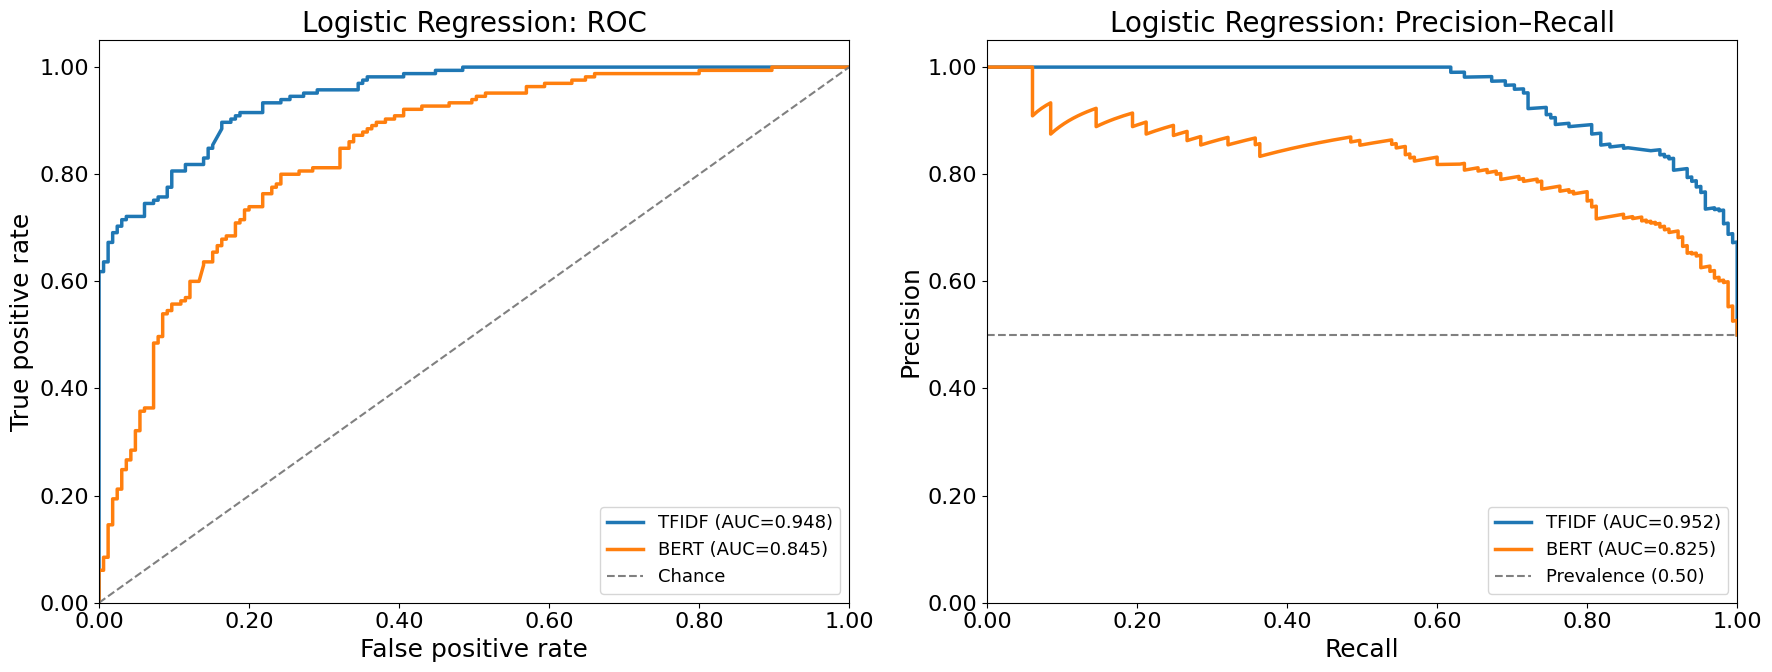

,classifier,embedding,train_images,test_images,accuracy,precision,recall,f1,macro_f1,roc_auc,pr_auc
0,Logistic Regression,tfidf,770,330,0.84,0.86,0.82,0.84,0.84,0.95,0.95
1,Logistic Regression,bert,770,330,0.76,0.80,0.71,0.75,0.76,0.85,0.82


In [85]:
logistic_summary = show_classifier_results(
    "Logistic Regression",
    logistic_results,
    classification_data,
    CLASSIFICATION_RESULTS_DIR / "logistic_regression",
)

## XGBoost

Use 200 shallow boosted trees with depth 3 and learning rate 0.05. The histogram algorithm runs on the CPU; settings stay identical across embeddings and are not tuned on held-out data.

In [86]:
def run_xgboost(classification_data):
    """Train and evaluate CPU XGBoost once per embedding type.

    Args:
        classification_data (dict): Shared feature splits and labels.

    Returns:
        dict: TF-IDF and BERT evaluation results.
    """
    classifier = XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        device="cpu",
        n_jobs=4,
        random_state=42,
    )
    return evaluate_embeddings(classifier, classification_data)

In [87]:
xgboost_results = run_xgboost(classification_data)

XGBoost | TFIDF


,precision,recall,f1-score,support
class,,,,
non_alcohol,0.906,0.703,0.792,165
alcohol,0.757,0.927,0.834,165
macro avg,0.832,0.815,0.813,330
weighted avg,0.832,0.815,0.813,330


ROC AUC: 0.899 | PR AUC: 0.904
XGBoost | BERT


,precision,recall,f1-score,support
class,,,,
non_alcohol,0.726,0.739,0.733,165
alcohol,0.735,0.721,0.728,165
macro avg,0.730,0.730,0.730,330
weighted avg,0.730,0.730,0.730,330


ROC AUC: 0.806 | PR AUC: 0.793


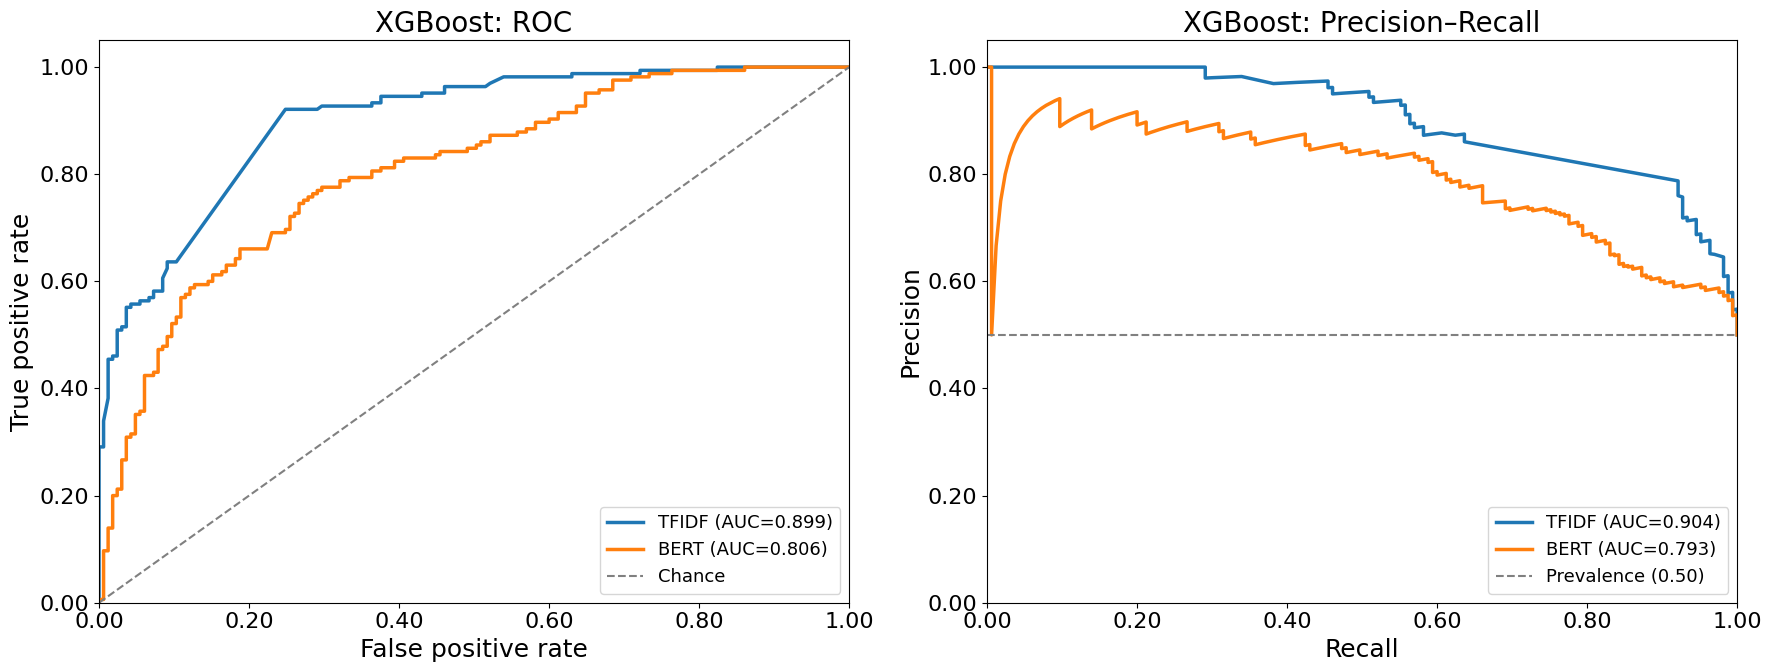

,classifier,embedding,train_images,test_images,accuracy,precision,recall,f1,macro_f1,roc_auc,pr_auc
0,XGBoost,tfidf,770,330,0.82,0.76,0.93,0.83,0.81,0.90,0.90
1,XGBoost,bert,770,330,0.73,0.73,0.72,0.73,0.73,0.81,0.79


In [88]:
xgboost_summary = show_classifier_results(
    "XGBoost",
    xgboost_results,
    classification_data,
    CLASSIFICATION_RESULTS_DIR / "xgboost",
)

## Random Forest

Use 200 bagged trees with at least two training images per leaf. Keep the random seed and settings fixed for both embedding types.

In [89]:
def run_random_forest(classification_data):
    """Train and evaluate Random Forest once per embedding type.

    Args:
        classification_data (dict): Shared feature splits and labels.

    Returns:
        dict: TF-IDF and BERT evaluation results.
    """
    classifier = RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, n_jobs=4, random_state=42
    )
    return evaluate_embeddings(classifier, classification_data)

In [90]:
random_forest_results = run_random_forest(classification_data)

Random Forest | TFIDF


,precision,recall,f1-score,support
class,,,,
non_alcohol,0.772,0.800,0.786,165
alcohol,0.792,0.764,0.778,165
macro avg,0.782,0.782,0.782,330
weighted avg,0.782,0.782,0.782,330


ROC AUC: 0.901 | PR AUC: 0.908
Random Forest | BERT


,precision,recall,f1-score,support
class,,,,
non_alcohol,0.716,0.764,0.739,165
alcohol,0.747,0.697,0.721,165
macro avg,0.731,0.730,0.730,330
weighted avg,0.731,0.730,0.730,330


ROC AUC: 0.818 | PR AUC: 0.821


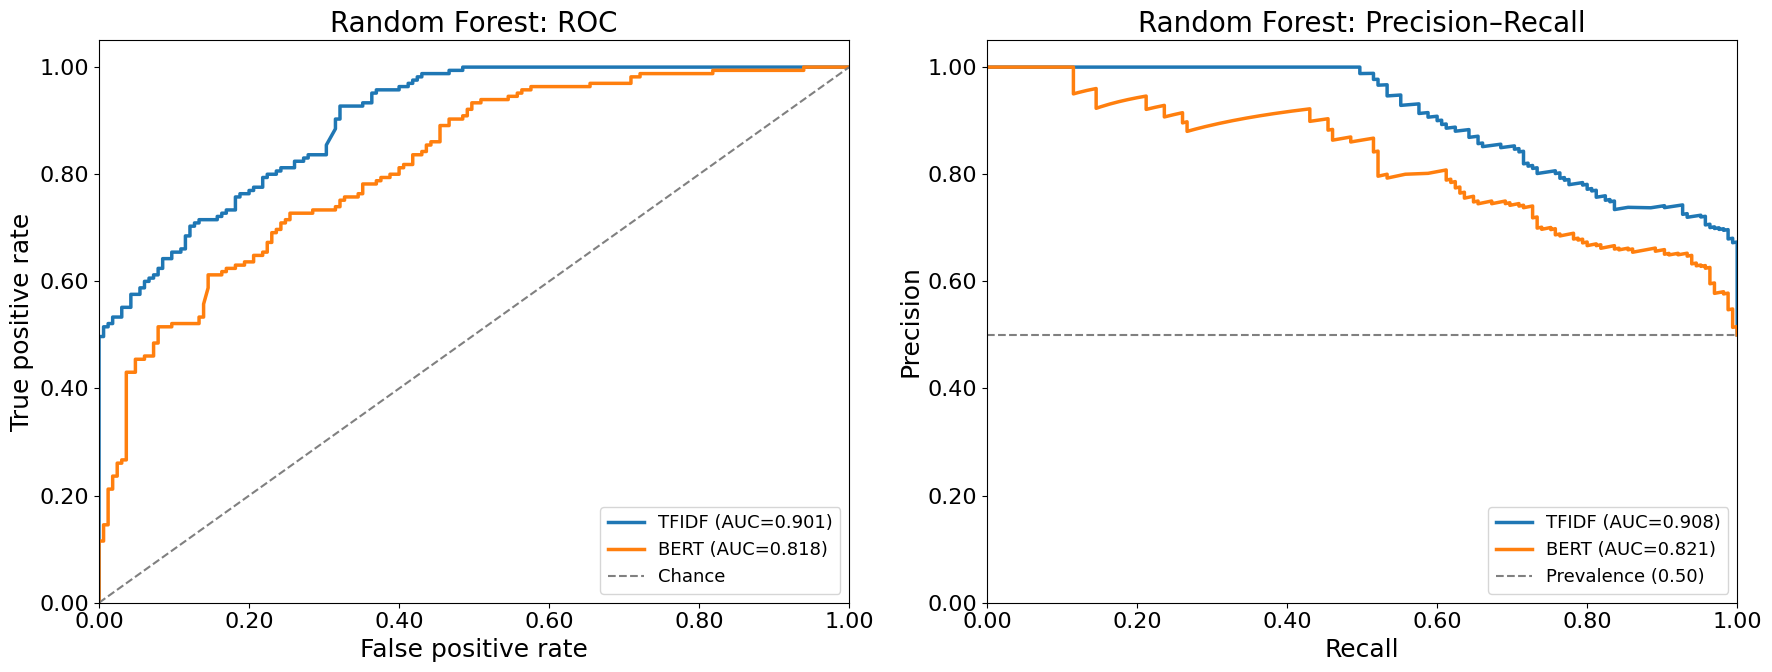

,classifier,embedding,train_images,test_images,accuracy,precision,recall,f1,macro_f1,roc_auc,pr_auc
0,Random Forest,tfidf,770,330,0.78,0.79,0.76,0.78,0.78,0.90,0.91
1,Random Forest,bert,770,330,0.73,0.75,0.70,0.72,0.73,0.82,0.82


In [91]:
random_forest_summary = show_classifier_results(
    "Random Forest",
    random_forest_results,
    classification_data,
    CLASSIFICATION_RESULTS_DIR / "random_forest",
)

## Performance Comparison

Compare all six runs on the same held-out images. Precision, recall, and F1 below refer to `alcohol`; macro F1 gives both classes equal weight. The per-class reports remain available in each classifier's TF-IDF and BERT subfolders.

In [92]:
def compare_classifiers(summaries):
    """Combine classifier summaries into one comparison table.

    Args:
        summaries (list[pd.DataFrame]): Per-classifier embedding summaries.

    Returns:
        pd.DataFrame: All classifier and embedding metrics, sorted by PR AUC
            and then ROC AUC for display.
    """
    return (
        pd.concat(summaries, ignore_index=True)
        .sort_values(["pr_auc", "roc_auc"], ascending=False)
        .reset_index(drop=True)
    )

In [93]:
performance_comparison = compare_classifiers(
    [logistic_summary, xgboost_summary, random_forest_summary]
)

,classifier,embedding,train_images,test_images,accuracy,precision,recall,f1,macro_f1,roc_auc,pr_auc
0,Logistic Regression,tfidf,770,330,0.842,0.855,0.824,0.840,0.842,0.948,0.952
1,Random Forest,tfidf,770,330,0.782,0.792,0.764,0.778,0.782,0.901,0.908
2,XGBoost,tfidf,770,330,0.815,0.757,0.927,0.834,0.813,0.899,0.904
3,Logistic Regression,bert,770,330,0.764,0.796,0.709,0.750,0.763,0.845,0.825
4,Random Forest,bert,770,330,0.730,0.747,0.697,0.721,0.730,0.818,0.821
5,XGBoost,bert,770,330,0.730,0.735,0.721,0.728,0.730,0.806,0.793


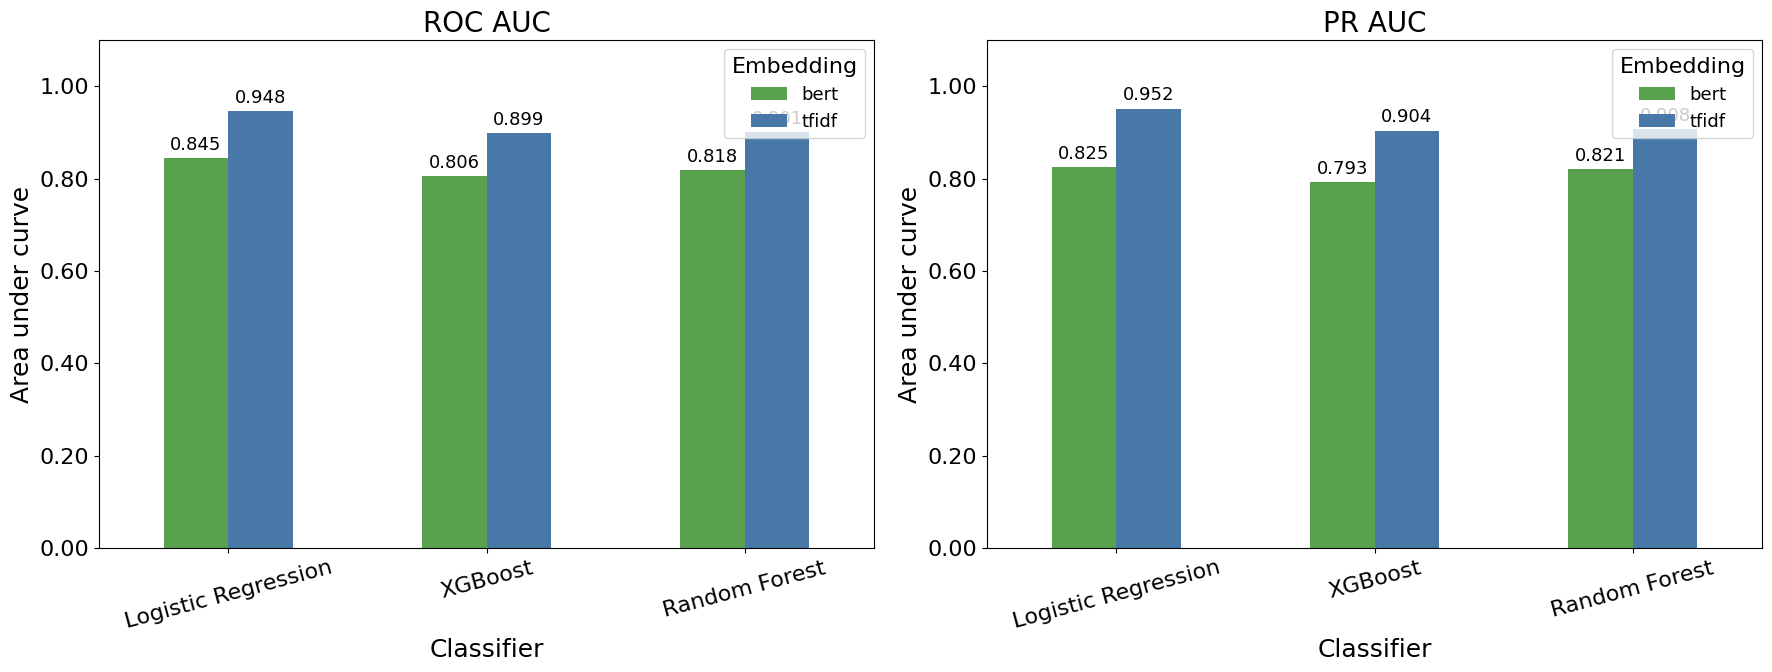

In [94]:
display(
    performance_comparison.style.format(
        {
            column: "{:,.3f}"
            for column in [
                "accuracy",
                "precision",
                "recall",
                "f1",
                "macro_f1",
                "roc_auc",
                "pr_auc",
            ]
        }
        | {"train_images": "{:,.0f}", "test_images": "{:,.0f}"}
    )
)
performance_comparison.to_csv(
    CLASSIFICATION_RESULTS_DIR / "performance_comparison.csv", index=False
)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for axis, metric, title in zip(
    axes, ["roc_auc", "pr_auc"], ["ROC AUC", "PR AUC"]
):
    comparison_plot = performance_comparison.pivot(
        index="classifier", columns="embedding", values=metric
    ).reindex(["Logistic Regression", "XGBoost", "Random Forest"])
    comparison_plot.plot.bar(ax=axis, rot=15, color=["#59A14F", "#4878A8"])
    axis.set(
        title=title,
        xlabel="Classifier",
        ylabel="Area under curve",
        ylim=(0, 1.1),
    )
    axis.yaxis.set_major_formatter(StrMethodFormatter("{x:,.2f}"))
    axis.legend(title="Embedding", fontsize=13)
    for container in axis.containers:
        axis.bar_label(container, fmt="{:,.3f}", padding=3, fontsize=13)
fig.tight_layout()
fig.savefig(
    CLASSIFICATION_RESULTS_DIR / "performance_comparison.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()